In [1]:
import pandas as pd
import numpy as np
import joblib

MODEL_PATH = r'C:\Users\215nt\PycharmProjects\FLStuff\FLHitting\simple_bat_speed_z_score_model.joblib'

features = ['launch_speed', 'height_inches', 'launch_angle', 'spray_angle', 'is_2_strikes']

# MLB column mapping
MLB_FEATURE_MAP = {
    'launch_speed':  'launch_speed',     # same name
    'launch_angle':  'launch_angle',     # same name
    'spray_angle':   'hc_x',            # closest proxy — hit coords
    'height_inches': 'age_bat',          # placeholder — see note below
    'is_2_strikes':  None,               # derived
}

def a_swing_mean(x):
    clean = x.dropna()
    if len(clean) < 5:
        return np.nan
    return clean[clean >= clean.quantile(0.10)].mean()


# ---------------------------------------------------------------
# 1. LOAD + FILTER TO BALLS IN PLAY WITH MEASURED BAT SPEED
# ---------------------------------------------------------------
print('Loading CSV...')
raw = pd.read_csv('2024_25_mlb_pitches.csv')
print(f'  raw rows: {len(raw):,}')

# Balls in play with actual bat speed readings
df = raw[
    (raw['description'] == 'hit_into_play') &
    raw['bat_speed'].notna() &
    raw['launch_speed'].notna() &
    raw['launch_angle'].notna()
].copy()
print(f'  BBE with bat_speed: {len(df):,}  |  batters: {df["batter"].nunique()}')

# Derive is_2_strikes
df['is_2_strikes'] = (df['strikes'] == 2).astype(int)

# height_inches isn't in Statcast — use a constant (or drop it if model allows)
# For now: fill with league-average height ~73 inches so it doesn't drive predictions
df['height_inches'] = 73.0

# hc_x as spray_angle proxy (not perfect, but directionally correct)
df['spray_angle'] = df['hc_x']

# Barrel flag: launch_speed_angle == 6 is Statcast barrel
df['is_barrel'] = (df['launch_speed_angle'] == 6).astype(int)


# ---------------------------------------------------------------
# 2. Z-SCORE FEATURES + PREDICT
# ---------------------------------------------------------------
model = joblib.load(MODEL_PATH)

X = pd.DataFrame(index=df.index)
for col in features:
    X[col] = (df[col] - df[col].mean()) / df[col].std()

df['pred_z_bat_speed'] = model.predict(X)

# Also z-score actual bat speed for apples-to-apples comparison
df['z_bat_speed_actual'] = (df['bat_speed'] - df['bat_speed'].mean()) / df['bat_speed'].std()

print(f'\nPrediction sanity check:')
print(df[['bat_speed', 'z_bat_speed_actual', 'pred_z_bat_speed']].describe().round(3))


# ---------------------------------------------------------------
# 3. AGGREGATE TO PLAYER LEVEL
# ---------------------------------------------------------------
def p90_ev(x):
    clean = x.dropna()
    return clean.quantile(0.90) if len(clean) >= 5 else np.nan

player = df.groupby('batter').agg(
    bbe=('launch_speed', 'count'),
    # predicted bat speed (our metric)
    pred_bs=('pred_z_bat_speed', a_swing_mean),
    # actual bat speed (ground truth)
    actual_bs=('bat_speed', a_swing_mean),
    actual_bs_mean=('bat_speed', 'mean'),
    # outcome stats
    p90_ev=('launch_speed', p90_ev),
    mean_ev=('launch_speed', 'mean'),
    barrel_rate=('is_barrel', 'mean'),
    mean_la=('launch_angle', 'mean'),
    xwoba=('estimated_woba_using_speedangle', 'mean'),
    xslg=('estimated_slg_using_speedangle', 'mean'),
).reset_index()

player = player[player['bbe'] >= 50].dropna().copy()
print(f'\nQualified players (>= 50 BBE): {len(player)}')


# ---------------------------------------------------------------
# 4. CORRELATIONS
# ---------------------------------------------------------------
outcome_cols = ['p90_ev', 'mean_ev', 'barrel_rate', 'xwoba', 'xslg', 'mean_la']

print('\n--- Predicted bat speed (a_swing_mean) vs outcomes ---')
pred_corrs = player[['pred_bs'] + outcome_cols].corr()['pred_bs'].drop('pred_bs')
print(pred_corrs.round(4))

print('\n--- Actual bat speed (a_swing_mean) vs outcomes ---')
actual_corrs = player[['actual_bs'] + outcome_cols].corr()['actual_bs'].drop('actual_bs')
print(actual_corrs.round(4))

print('\n--- Predicted vs Actual bat speed (model validation) ---')
r_pred_actual = player[['pred_bs', 'actual_bs']].corr().iloc[0, 1]
print(f'r(pred, actual) = {r_pred_actual:.4f}')

print('\n--- Side-by-side: predicted vs actual correlations ---')
comparison = pd.DataFrame({
    'pred_r':   pred_corrs,
    'actual_r': actual_corrs,
    'delta':    (pred_corrs - actual_corrs).round(4)
})
print(comparison.round(4).to_string())

Loading CSV...
  raw rows: 1,531,043
  BBE with bat_speed: 236,705  |  batters: 881

Prediction sanity check:
        bat_speed  z_bat_speed_actual  pred_z_bat_speed
count  236705.000          236705.000        236705.000
mean       71.077              -0.000             0.639
std         7.063               1.000             0.568
min         1.300              -9.879            -8.146
25%        68.300              -0.393             0.577
50%        71.800               0.102             0.703
75%        74.900               0.541             0.843
max        88.000               2.396             2.095

Qualified players (>= 50 BBE): 598

--- Predicted bat speed (a_swing_mean) vs outcomes ---
p90_ev         0.7269
mean_ev        0.7625
barrel_rate    0.7411
xwoba          0.6201
xslg           0.7051
mean_la        0.4870
Name: pred_bs, dtype: float64

--- Actual bat speed (a_swing_mean) vs outcomes ---
p90_ev         0.9081
mean_ev        0.7303
barrel_rate    0.7266
xwoba        

Pulled 33,251 2025 FL BBE  |  232 batters
Players with H1 + H2 >= 25 BBE each: 184
Whole-season qualified (>= 25 BBE): 198

--- In-sample vs H1→H2 predictive validity ---
    in-sample n=198  |  H1→H2 n=184
             in_sample_r  h1_to_h2_r  shrinkage
p90_ev            0.7973      0.7235      0.907
mean_ev           0.7427      0.6495      0.875
barrel_rate       0.6118      0.5354      0.875
avg               0.3381      0.1972      0.583
slg_bbe           0.5610      0.4336      0.773
xdamage           0.5745      0.4508      0.785
distance          0.4603      0.4499      0.977


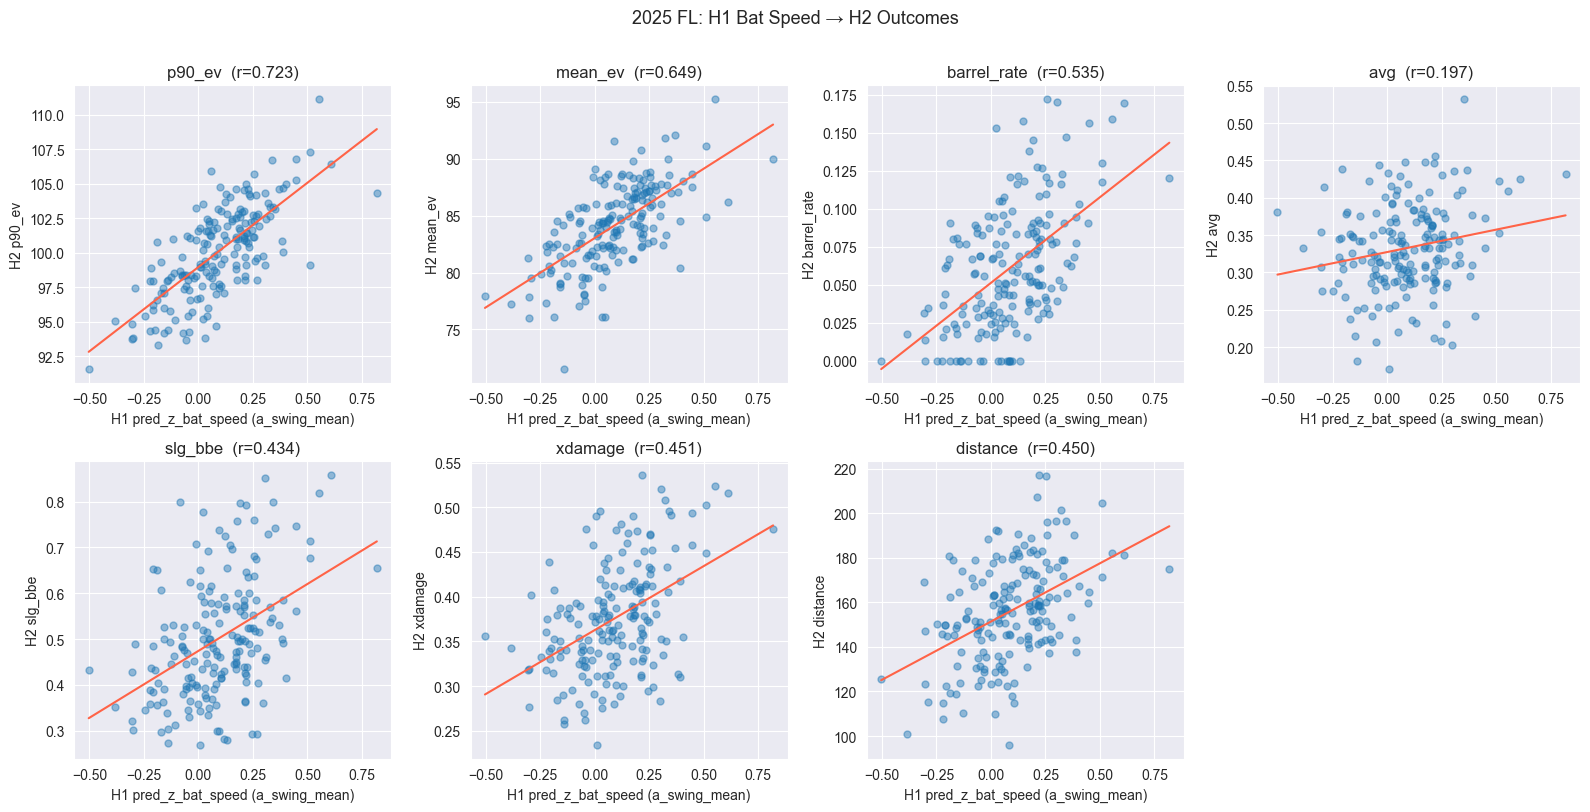

In [21]:
import numpy as np
import pandas as pd
import joblib
from sqlalchemy import create_engine, text
import os
import matplotlib.pyplot as plt

MODEL_PATH = r'C:\Users\215nt\PycharmProjects\FLStuff\FLHitting\simple_bat_speed_z_score_model.joblib'
features   = ['launch_speed', 'height_inches', 'launch_angle', 'spray_angle', 'is_2_strikes']

SUPABASE = {
    'host':     'aws-1-us-east-1.pooler.supabase.com',
    'port':     6543,
    'database': 'postgres',
    'user':     'postgres.zqspccujqmbzsxulnrqt',
    'password': 'REMOVED-see-secrets.toml',
}

def get_engine():
    cfg = SUPABASE
    url = (f"postgresql+psycopg2://{cfg['user']}:{cfg['password']}"
           f"@{cfg['host']}:{cfg['port']}/{cfg['database']}")
    return create_engine(url, pool_pre_ping=True,
                         connect_args={'sslmode': 'require'})

def a_swing_mean(x):
    clean = x.dropna()
    if len(clean) < 5: return np.nan
    return clean[clean >= clean.quantile(0.10)].mean()

def p90_ev(x):
    clean = x.dropna()
    return clean.quantile(0.90) if len(clean) >= 5 else np.nan


# ---------------------------------------------------------------
# 1. PULL 2025 FL BBE
# ---------------------------------------------------------------
q = text("""
    SELECT
        batter_id,
        batter,
        date,
        exit_speed   AS launch_speed,
        angle        AS launch_angle,
        direction    AS spray_angle,
        height_in    AS height_inches,
        strikes,
        play_result,
        distance,
        xdamage,
        barrel
    FROM pitches
    WHERE date::timestamp >= '2025-05-07'
      AND date::timestamp <= '2025-12-31'
      AND pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
""")

with get_engine().connect() as conn:
    df = pd.read_sql(q, conn)

df.columns     = [c.lower().strip() for c in df.columns]
df['date']     = pd.to_datetime(df['date'])
df['is_2_strikes'] = (df['strikes'] == 2).astype(int)
df = df.dropna(subset=['launch_speed', 'launch_angle', 'spray_angle', 'height_inches']).copy()

# Outcome flags
hit_results  = ['single', 'double', 'triple', 'home_run']
bases_map    = {'single': 1, 'double': 2, 'triple': 3, 'home_run': 4}
df['is_hit'] = df['play_result'].isin(hit_results).astype(int)
df['bases']  = df['play_result'].map(bases_map).fillna(0)
df['is_barrel'] = (
    df['barrel'] == 1
).astype(int)

print(f'Pulled {len(df):,} 2025 FL BBE  |  {df["batter_id"].nunique()} batters')


# ---------------------------------------------------------------
# 2. Z-SCORE FEATURES + PREDICT (on full dataset for consistent scaling)
# ---------------------------------------------------------------
model = joblib.load(MODEL_PATH)

X = pd.DataFrame(index=df.index)
for col in features:
    X[col] = (df[col] - df[col].mean()) / df[col].std()

df['pred_z_bat_speed'] = model.predict(X)


# ---------------------------------------------------------------
# 3. CHRONOLOGICAL H1 / H2 SPLIT (within each player)
# ---------------------------------------------------------------
df = df.sort_values(['batter_id', 'date']).copy()
df['bbe_rank']       = df.groupby('batter_id').cumcount()
df['n_bbe_player']   = df.groupby('batter_id')['bbe_rank'].transform('count')
df['half']           = np.where(df['bbe_rank'] < df['n_bbe_player'] / 2, 'H1', 'H2')

MIN_BBE_HALF = 25 # each half independently needs this many BBE

# H1: bat speed predictor
h1 = (df[df['half'] == 'H1']
      .groupby(['batter_id', 'batter'])
      .agg(
          h1_bs    = ('pred_z_bat_speed', a_swing_mean),
          h1_bbe   = ('pred_z_bat_speed', lambda x: x.dropna().shape[0]),
      ).reset_index())

# H2: outcome targets
h2 = (df[df['half'] == 'H2']
      .groupby(['batter_id', 'batter'])
      .agg(
          h2_bbe         = ('launch_speed', 'count'),
          h2_p90_ev      = ('launch_speed', p90_ev),
          h2_mean_ev     = ('launch_speed', 'mean'),
          h2_barrel_rate = ('is_barrel', 'mean'),
          h2_avg         = ('is_hit', 'mean'),
          h2_slg_bbe     = ('bases', 'mean'),
          h2_xdamage     = ('xdamage', 'mean'),
          h2_distance    = ('distance', 'mean'),
      ).reset_index())

split = (h1.merge(h2, on=['batter_id', 'batter'], how='inner')
           .query('h1_bbe >= @MIN_BBE_HALF and h2_bbe >= @MIN_BBE_HALF')
           .dropna(subset=['h1_bs'])
           .copy())

print(f'Players with H1 + H2 >= {MIN_BBE_HALF} BBE each: {len(split)}')


# ---------------------------------------------------------------
# 4. WHOLE-SEASON AGGREGATION (for in-sample comparison)
# ---------------------------------------------------------------
whole = (df.groupby(['batter_id', 'batter'])
           .agg(
               bbe         = ('launch_speed', 'count'),
               pred_bs     = ('pred_z_bat_speed', a_swing_mean),
               p90_ev      = ('launch_speed', p90_ev),
               mean_ev     = ('launch_speed', 'mean'),
               barrel_rate = ('is_barrel', 'mean'),
               avg         = ('is_hit', 'mean'),
               slg_bbe     = ('bases', 'mean'),
               xdamage     = ('xdamage', 'mean'),
               distance    = ('distance', 'mean'),
           ).reset_index()
           .query('bbe >= 25')
           .dropna(subset=['pred_bs'])
           .copy())

print(f'Whole-season qualified (>= 25 BBE): {len(whole)}')


# ---------------------------------------------------------------
# 5. CORRELATIONS
# ---------------------------------------------------------------
outcome_cols    = ['p90_ev', 'mean_ev', 'barrel_rate', 'avg',
                   'slg_bbe', 'xdamage', 'distance']
h2_outcome_cols = [f'h2_{c}' for c in outcome_cols]

in_sample_corrs = (whole[['pred_bs'] + outcome_cols]
                   .corr()['pred_bs'].drop('pred_bs'))

out_sample_corrs = (split[['h1_bs'] + h2_outcome_cols]
                    .corr()['h1_bs'].drop('h1_bs'))
out_sample_corrs.index = outcome_cols   # align index for comparison

comparison = pd.DataFrame({
    'in_sample_r':  in_sample_corrs,
    'h1_to_h2_r':   out_sample_corrs,
}).round(4)
comparison['shrinkage'] = (comparison['h1_to_h2_r'] / comparison['in_sample_r']).round(3)

print('\n--- In-sample vs H1→H2 predictive validity ---')
print(f'    in-sample n={len(whole)}  |  H1→H2 n={len(split)}')
print(comparison.to_string())


# ---------------------------------------------------------------
# 6. SCATTER GRID: H1 bat speed → H2 outcomes
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (col, h2_col) in enumerate(zip(outcome_cols, h2_outcome_cols)):
    r = split[['h1_bs', h2_col]].corr().iloc[0, 1]
    axes[i].scatter(split['h1_bs'], split[h2_col], alpha=0.45, s=25)
    m, b = np.polyfit(split['h1_bs'].dropna(),
                      split[h2_col].dropna(), 1)
    xs = np.linspace(split['h1_bs'].min(), split['h1_bs'].max(), 100)
    axes[i].plot(xs, m * xs + b, color='tomato', linewidth=1.5)
    axes[i].set_xlabel('H1 pred_z_bat_speed (a_swing_mean)')
    axes[i].set_ylabel(f'H2 {col}')
    axes[i].set_title(f'{col}  (r={r:.3f})')

axes[-1].set_visible(False)
plt.suptitle('2025 FL: H1 Bat Speed → H2 Outcomes', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

MLB BBE with bat_speed: 236,603  |  batters: 881
MLB players H1+H2 >= 50 BBE each: 509

--- MLB H1→H2: predicted vs actual bat speed (n=509) ---
             predicted_r  actual_r   delta
p90_ev            0.6855    0.8549 -0.1694
mean_ev           0.6205    0.6618 -0.0413
barrel_rate       0.6517    0.6683 -0.0166
avg               0.2724    0.3651 -0.0927
slg_bbe           0.5318    0.5563 -0.0245
xwoba             0.5719    0.6355 -0.0636
xslg              0.6268    0.6548 -0.0281


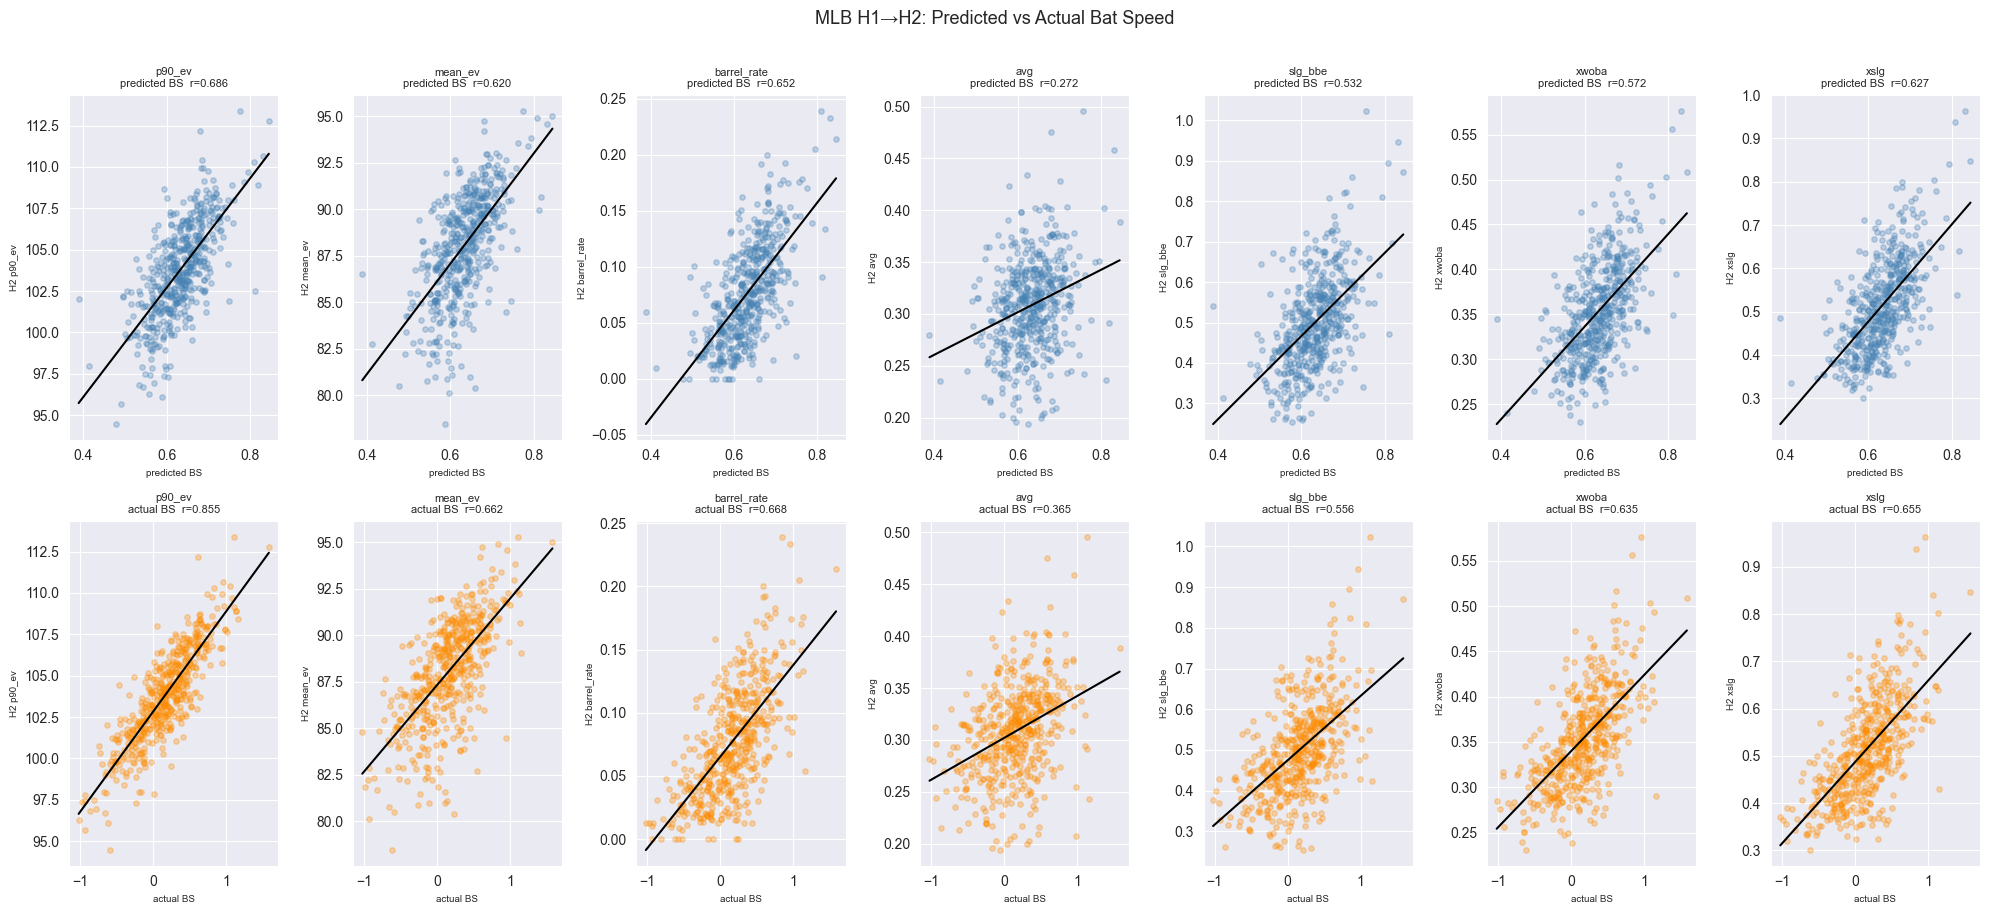

In [10]:
# ---------------------------------------------------------------
# MLB: H1 bat speed (predicted + actual) → H2 outcomes
# Uses 2024_25_mlb_pitches.csv loaded earlier as `raw`
# ---------------------------------------------------------------

# 1. FILTER + FEATURE ENGINEERING
mlb = raw[
    (raw['description'] == 'hit_into_play') &
    raw['bat_speed'].notna() &
    raw['launch_speed'].notna() &
    raw['launch_angle'].notna()
].copy()

mlb['is_2_strikes']  = (mlb['strikes'] == 2).astype(int)
mlb['height_inches'] = 73.0                          # not in Statcast — constant
mlb['spray_angle']   = mlb['hc_x']                  # proxy as before
mlb['game_date']     = pd.to_datetime(mlb['game_date'])

hit_results      = ['single', 'double', 'triple', 'home_run']
bases_map        = {'single': 1, 'double': 2, 'triple': 3, 'home_run': 4}
mlb['is_hit']    = mlb['events'].isin(hit_results).astype(int)
mlb['bases']     = mlb['events'].map(bases_map).fillna(0)
mlb['is_barrel'] = (mlb['launch_speed_angle'] == 6).astype(int)

mlb = mlb.dropna(subset=['launch_speed', 'launch_angle', 'spray_angle']).copy()
print(f'MLB BBE with bat_speed: {len(mlb):,}  |  batters: {mlb["batter"].nunique()}')


# 2. Z-SCORE FEATURES + PREDICT
X_mlb = pd.DataFrame(index=mlb.index)
for col in features:
    X_mlb[col] = (mlb[col] - mlb[col].mean()) / mlb[col].std()

mlb['pred_z_bat_speed']   = model.predict(X_mlb)
mlb['z_bat_speed_actual'] = (mlb['bat_speed'] - mlb['bat_speed'].mean()) / mlb['bat_speed'].std()


# 3. CHRONOLOGICAL H1/H2 SPLIT
mlb = mlb.sort_values(['batter', 'game_date']).copy()
mlb['bbe_rank']     = mlb.groupby('batter').cumcount()
mlb['n_bbe_player'] = mlb.groupby('batter')['bbe_rank'].transform('count')
mlb['half']         = np.where(mlb['bbe_rank'] < mlb['n_bbe_player'] / 2, 'H1', 'H2')

MLB_MIN_BBE_HALF = 50   # larger than FL given the bigger sample available

def agg_half(sub, prefix, bs_col):
    return (sub.groupby('batter')
               .agg(**{
                   f'{prefix}_bs':          (bs_col,              a_swing_mean),
                   f'{prefix}_bbe':         ('launch_speed',      'count'),
                   f'{prefix}_p90_ev':      ('launch_speed',      p90_ev),
                   f'{prefix}_mean_ev':     ('launch_speed',      'mean'),
                   f'{prefix}_barrel_rate': ('is_barrel',         'mean'),
                   f'{prefix}_avg':         ('is_hit',            'mean'),
                   f'{prefix}_slg_bbe':     ('bases',             'mean'),
                   f'{prefix}_xwoba':       ('estimated_woba_using_speedangle', 'mean'),
                   f'{prefix}_xslg':        ('estimated_slg_using_speedangle',  'mean'),
               }).reset_index())

# Build splits for BOTH predicted and actual bat speed
h1_pred   = agg_half(mlb[mlb['half'] == 'H1'], 'h1_pred',   'pred_z_bat_speed')
h1_actual = agg_half(mlb[mlb['half'] == 'H1'], 'h1_actual', 'z_bat_speed_actual')

h2 = (mlb[mlb['half'] == 'H2']
      .groupby('batter')
      .agg(
          h2_bbe         = ('launch_speed',                       'count'),
          h2_p90_ev      = ('launch_speed',                       p90_ev),
          h2_mean_ev     = ('launch_speed',                       'mean'),
          h2_barrel_rate = ('is_barrel',                          'mean'),
          h2_avg         = ('is_hit',                             'mean'),
          h2_slg_bbe     = ('bases',                              'mean'),
          h2_xwoba       = ('estimated_woba_using_speedangle',    'mean'),
          h2_xslg        = ('estimated_slg_using_speedangle',     'mean'),
      ).reset_index())

split_mlb = (h1_pred
             .merge(h1_actual[['batter', 'h1_actual_bs']], on='batter')
             .merge(h2, on='batter', how='inner')
             .query('h1_pred_bbe >= @MLB_MIN_BBE_HALF and h2_bbe >= @MLB_MIN_BBE_HALF')
             .dropna(subset=['h1_pred_bs', 'h1_actual_bs'])
             .copy())

print(f'MLB players H1+H2 >= {MLB_MIN_BBE_HALF} BBE each: {len(split_mlb)}')


# 4. CORRELATIONS: predicted vs actual, both → H2 outcomes
mlb_outcomes = ['p90_ev', 'mean_ev', 'barrel_rate', 'avg', 'slg_bbe', 'xwoba', 'xslg']
h2_cols      = [f'h2_{c}' for c in mlb_outcomes]

pred_corrs   = (split_mlb[['h1_pred_bs']   + h2_cols].corr()['h1_pred_bs']  .drop('h1_pred_bs'))
actual_corrs = (split_mlb[['h1_actual_bs'] + h2_cols].corr()['h1_actual_bs'].drop('h1_actual_bs'))
pred_corrs.index   = mlb_outcomes
actual_corrs.index = mlb_outcomes

comparison_mlb = pd.DataFrame({
    'predicted_r': pred_corrs,
    'actual_r':    actual_corrs,
    'delta':       (pred_corrs - actual_corrs).round(4),
}).round(4)

print(f'\n--- MLB H1→H2: predicted vs actual bat speed (n={len(split_mlb)}) ---')
print(comparison_mlb.to_string())


# 5. SCATTER GRID
fig, axes = plt.subplots(2, len(mlb_outcomes), figsize=(20, 9), sharey=False)

for i, (col, h2_col) in enumerate(zip(mlb_outcomes, h2_cols)):
    for ax, bs_col, label, color in zip(
        [axes[0, i], axes[1, i]],
        ['h1_pred_bs',   'h1_actual_bs'],
        ['predicted BS', 'actual BS'],
        ['steelblue',    'darkorange'],
    ):
        r = split_mlb[[bs_col, h2_col]].corr().iloc[0, 1]
        ax.scatter(split_mlb[bs_col], split_mlb[h2_col],
                   alpha=0.3, s=15, color=color)
        xs = np.linspace(split_mlb[bs_col].min(), split_mlb[bs_col].max(), 100)
        m, b = np.polyfit(split_mlb[bs_col].dropna(),
                          split_mlb[h2_col].dropna(), 1)
        ax.plot(xs, m * xs + b, color='black', linewidth=1.5)
        ax.set_title(f'{col}\n{label}  r={r:.3f}', fontsize=8)
        ax.set_xlabel(label, fontsize=7)
        ax.set_ylabel(f'H2 {col}', fontsize=7)

plt.suptitle('MLB H1→H2: Predicted vs Actual Bat Speed', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Pulled 12,242 2026 FL BBE  |  240 batters
2026 qualified (>= 25 BBE): 189

--- FL in-sample: 2025 vs 2026 ---
             2025_r (n=198)  2026_r (n=189)
p90_ev               0.7973          0.7755
mean_ev              0.7427          0.7371
barrel_rate          0.6118          0.5438
avg                  0.3381          0.2353
slg_bbe              0.5610          0.4133
xdamage              0.5745          0.5348
distance             0.4603          0.3565


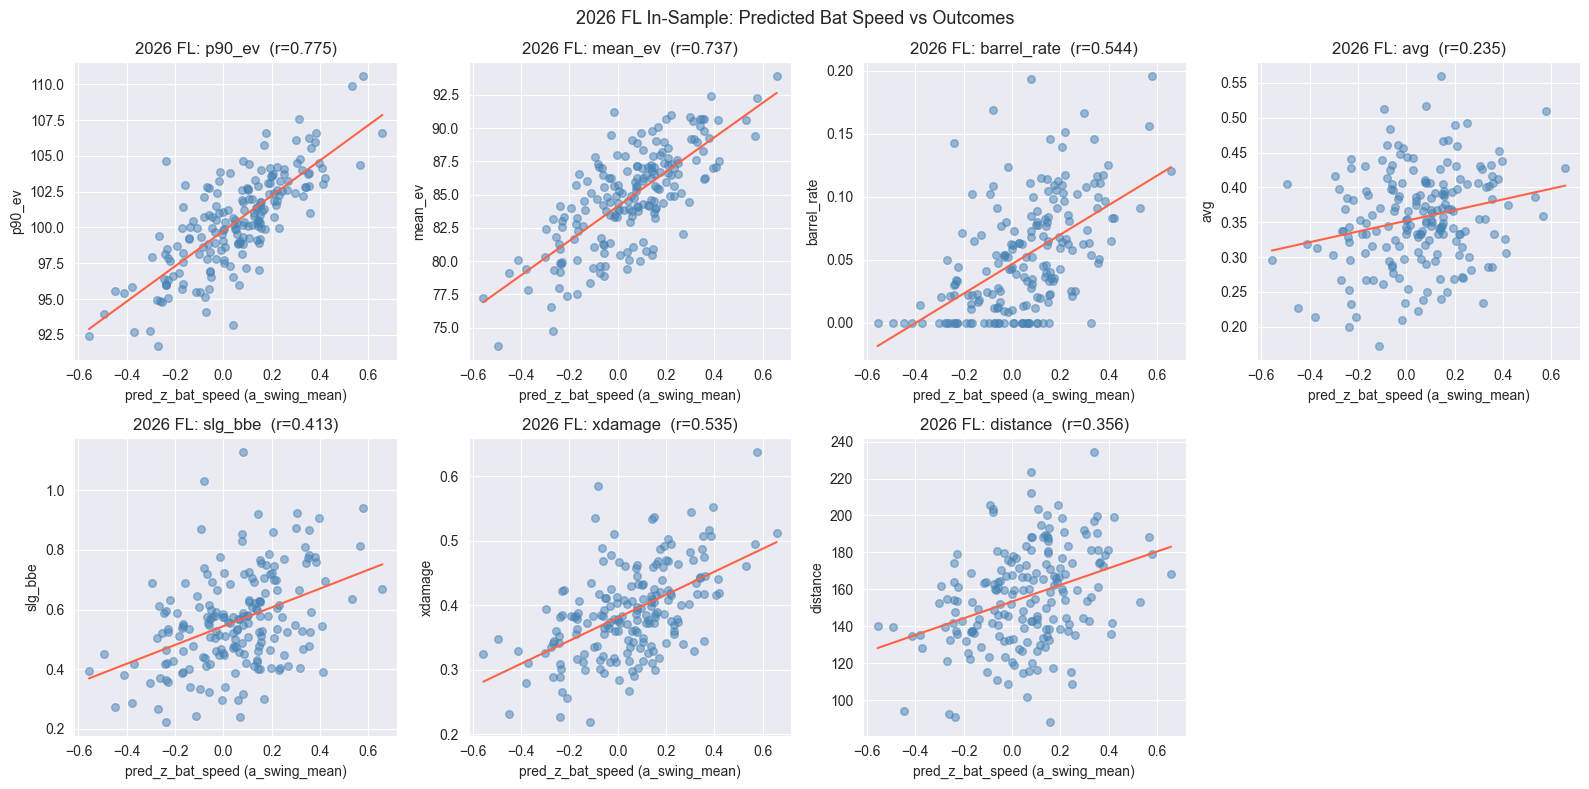

In [17]:
# ---------------------------------------------------------------
# 2026 FL: in-sample correlations (whole season, same structure)
# ---------------------------------------------------------------

q_2026 = text("""
    SELECT
        batter_id,
        batter,
        date,
        exit_speed   AS launch_speed,
        angle        AS launch_angle,
        direction    AS spray_angle,
        height_in    AS height_inches,
        strikes,
        play_result,
        distance,
        barrel,
        xdamage
    FROM pitches
    WHERE date::timestamp >= '2026-05-07'
      AND date::timestamp <= '2026-12-31'
      AND pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
""")

with get_engine().connect() as conn:
    df_2026 = pd.read_sql(q_2026, conn)

df_2026.columns      = [c.lower().strip() for c in df_2026.columns]
df_2026['date']      = pd.to_datetime(df_2026['date'])
df_2026['is_2_strikes'] = (df_2026['strikes'] == 2).astype(int)
df_2026 = df_2026.dropna(subset=['launch_speed', 'launch_angle',
                                  'spray_angle', 'height_inches']).copy()

df_2026['is_hit']    = df_2026['play_result'].isin(hit_results).astype(int)
df_2026['bases']     = df_2026['play_result'].map(bases_map).fillna(0)
df_2026['is_barrel'] = (
    df_2026['barrel'] == 1
).astype(int)

print(f'Pulled {len(df_2026):,} 2026 FL BBE  |  {df_2026["batter_id"].nunique()} batters')

# Z-score features + predict (scale within 2026 pool)
X_2026 = pd.DataFrame(index=df_2026.index)
for col in features:
    X_2026[col] = (df_2026[col] - df_2026[col].mean()) / df_2026[col].std()

df_2026['pred_z_bat_speed'] = model.predict(X_2026)

# Aggregate to player level
whole_2026 = (df_2026.groupby(['batter_id', 'batter'])
              .agg(
                  bbe         = ('launch_speed',  'count'),
                  pred_bs     = ('pred_z_bat_speed', a_swing_mean),
                  p90_ev      = ('launch_speed',  p90_ev),
                  mean_ev     = ('launch_speed',  'mean'),
                  barrel_rate = ('is_barrel',     'mean'),
                  avg         = ('is_hit',        'mean'),
                  slg_bbe     = ('bases',         'mean'),
                  xdamage     = ('xdamage',       'mean'),
                  distance    = ('distance',      'mean'),
              ).reset_index()
              .query('bbe >= 25')       # relaxed threshold — ST sample
              .dropna(subset=['pred_bs'])
              .copy())

print(f'2026 qualified (>= 25 BBE): {len(whole_2026)}')

# Correlations
outcome_cols_fl = ['p90_ev', 'mean_ev', 'barrel_rate', 'avg',
                   'slg_bbe', 'xdamage', 'distance']

corrs_2025 = (whole[['pred_bs'] + outcome_cols_fl]
              .corr()['pred_bs'].drop('pred_bs'))
corrs_2026 = (whole_2026[['pred_bs'] + outcome_cols_fl]
              .corr()['pred_bs'].drop('pred_bs'))

comparison_fl = pd.DataFrame({
    f'2025_r (n={len(whole)})':    corrs_2025,
    f'2026_r (n={len(whole_2026)})': corrs_2026,
}).round(4)

print('\n--- FL in-sample: 2025 vs 2026 ---')
print(comparison_fl.to_string())

# Scatter grid — 2026
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(outcome_cols_fl):
    sub = whole_2026[['pred_bs', col]].dropna()
    r   = sub.corr().iloc[0, 1]
    axes[i].scatter(sub['pred_bs'], sub[col], alpha=0.5, s=30, color='steelblue')
    if len(sub) >= 3:
        m, b = np.polyfit(sub['pred_bs'], sub[col], 1)
        xs   = np.linspace(sub['pred_bs'].min(), sub['pred_bs'].max(), 100)
        axes[i].plot(xs, m * xs + b, color='tomato', linewidth=1.5)
    axes[i].set_xlabel('pred_z_bat_speed (a_swing_mean)')
    axes[i].set_ylabel(col)
    axes[i].set_title(f'2026 FL: {col}  (r={r:.3f})')

axes[-1].set_visible(False)
plt.suptitle('2026 FL In-Sample: Predicted Bat Speed vs Outcomes', fontsize=13)
plt.tight_layout()
plt.show()

2025 FL: 198 players  |  2026 FL: 211 players
2025 FL H1→H2: 195 players

--- Metric comparison: Predicted BS vs Mean EV vs p90 EV ---
predictor                         Mean EV  Predicted BS  p90 EV
dataset           outcome                                      
2025 FL H1→H2     h2_avg           0.1771        0.1421  0.2421
                  h2_barrel_rate   0.4817        0.5146  0.5821
                  h2_distance      0.4258        0.3827  0.3534
                  h2_slg_bbe       0.3840        0.3857  0.4978
                  h2_xdamage       0.4405        0.4068  0.5383
2025 FL in-sample avg              0.4873        0.3381  0.4862
                  barrel_rate      0.7022        0.6118  0.7539
                  distance         0.5965        0.4603  0.4668
                  slg_bbe          0.6740        0.5610  0.7211
                  xdamage          0.7594        0.5745  0.7613
2026 FL in-sample avg              0.4494        0.2567  0.3870
                  barrel_rate    

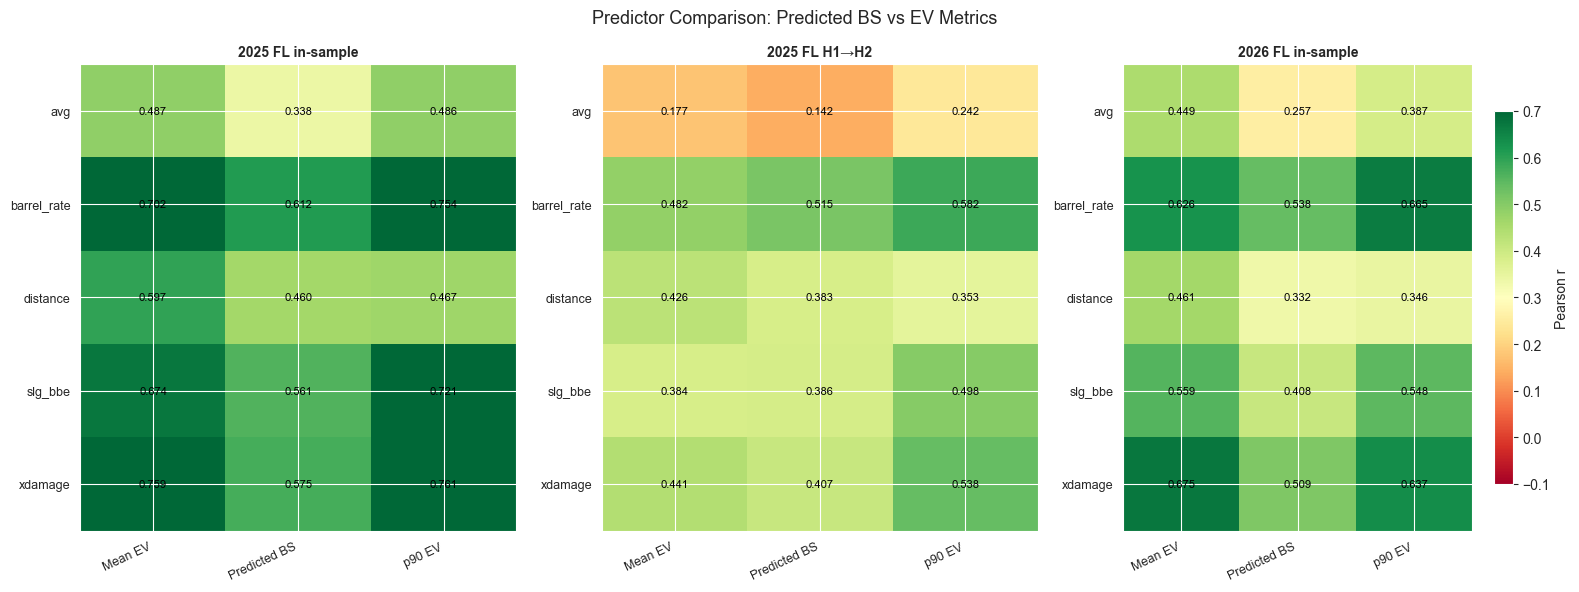

In [22]:
# ---------------------------------------------------------------
# Metric comparison: pred_z_bat_speed vs mean_ev vs p90_ev
# All three datasets, all outcomes, in-sample + H1→H2 where available
# ---------------------------------------------------------------

metrics = {
    'pred_bs':  'Predicted BS',
    'mean_ev':  'Mean EV',
    'p90_ev':   'p90 EV',
}

outcome_cols_fl  = ['barrel_rate', 'avg', 'slg_bbe', 'xdamage', 'distance']
outcome_cols_mlb = ['barrel_rate', 'avg', 'slg_bbe', 'xwoba', 'xslg']


# ---------------------------------------------------------------
# 1. RE-PULL 2025 FL with actual barrel column
# ---------------------------------------------------------------
q_2025 = text("""
    SELECT
        batter_id,
        batter,
        date,
        exit_speed      AS launch_speed,
        angle           AS launch_angle,
        direction       AS spray_angle,
        height_in       AS height_inches,
        strikes,
        play_result,
        distance,
        xdamage,
        barrel
    FROM pitches
    WHERE date::timestamp >= '2025-01-01'
      AND date::timestamp <= '2025-12-31'
      AND pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
""")

with get_engine().connect() as conn:
    df_2025 = pd.read_sql(q_2025, conn)

df_2025.columns      = [c.lower().strip() for c in df_2025.columns]
df_2025['date']      = pd.to_datetime(df_2025['date'])
df_2025['is_2_strikes'] = (df_2025['strikes'] == 2).astype(int)
df_2025 = df_2025.dropna(subset=['launch_speed', 'launch_angle',
                                  'spray_angle', 'height_inches']).copy()

df_2025['is_hit']    = df_2025['play_result'].isin(hit_results).astype(int)
df_2025['bases']     = df_2025['play_result'].map(bases_map).fillna(0)
df_2025['barrel']    = pd.to_numeric(df_2025['barrel'], errors='coerce').fillna(0).astype(int)

# Z-score + predict
X_2025 = pd.DataFrame(index=df_2025.index)
for col in features:
    X_2025[col] = (df_2025[col] - df_2025[col].mean()) / df_2025[col].std()
df_2025['pred_z_bat_speed'] = model.predict(X_2025)


# ---------------------------------------------------------------
# 2. RE-PULL 2026 FL with actual barrel column
# ---------------------------------------------------------------
q_2026 = text("""
    SELECT
        batter_id,
        batter,
        date,
        exit_speed      AS launch_speed,
        angle           AS launch_angle,
        direction       AS spray_angle,
        height_in       AS height_inches,
        strikes,
        play_result,
        distance,
        xdamage,
        barrel
    FROM pitches
    WHERE date::timestamp >= '2026-01-01'
      AND date::timestamp <= '2026-12-31'
      AND pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
""")

with get_engine().connect() as conn:
    df_2026 = pd.read_sql(q_2026, conn)

df_2026.columns      = [c.lower().strip() for c in df_2026.columns]
df_2026['date']      = pd.to_datetime(df_2026['date'])
df_2026['is_2_strikes'] = (df_2026['strikes'] == 2).astype(int)
df_2026 = df_2026.dropna(subset=['launch_speed', 'launch_angle',
                                  'spray_angle', 'height_inches']).copy()

df_2026['is_hit']    = df_2026['play_result'].isin(hit_results).astype(int)
df_2026['bases']     = df_2026['play_result'].map(bases_map).fillna(0)
df_2026['barrel']    = pd.to_numeric(df_2026['barrel'], errors='coerce').fillna(0).astype(int)

X_2026 = pd.DataFrame(index=df_2026.index)
for col in features:
    X_2026[col] = (df_2026[col] - df_2026[col].mean()) / df_2026[col].std()
df_2026['pred_z_bat_speed'] = model.predict(X_2026)


# ---------------------------------------------------------------
# 3. AGGREGATE HELPER
# ---------------------------------------------------------------
def aggregate_players(df, min_bbe=25):
    g = (df.groupby(['batter_id', 'batter'])
           .agg(
               bbe         = ('launch_speed', 'count'),
               pred_bs     = ('pred_z_bat_speed', a_swing_mean),
               mean_ev     = ('launch_speed', 'mean'),
               p90_ev      = ('launch_speed', p90_ev),
               barrel_rate = ('barrel', 'mean'),
               avg         = ('is_hit', 'mean'),
               slg_bbe     = ('bases', 'mean'),
               xdamage     = ('xdamage', 'mean'),
               distance    = ('distance', 'mean'),
           ).reset_index()
           .query('bbe >= @min_bbe')
           .dropna(subset=['pred_bs', 'mean_ev', 'p90_ev'])
           .copy())
    return g

whole_2025 = aggregate_players(df_2025, min_bbe=25)
whole_2026 = aggregate_players(df_2026, min_bbe=12)
print(f'2025 FL: {len(whole_2025)} players  |  2026 FL: {len(whole_2026)} players')


# ---------------------------------------------------------------
# 4. CORRELATION TABLE BUILDER
# ---------------------------------------------------------------
def corr_table(player_df, predictors, outcomes, label):
    rows = []
    for pred_col, pred_label in predictors.items():
        for out_col in outcomes:
            if pred_col not in player_df or out_col not in player_df:
                continue
            sub = player_df[[pred_col, out_col]].dropna()
            r   = sub.corr().iloc[0, 1] if len(sub) >= 10 else np.nan
            rows.append({'dataset': label, 'predictor': pred_label,
                         'outcome': out_col, 'r': round(r, 4), 'n': len(sub)})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------
# 5. H1→H2 FOR 2025 FL (reuse split from earlier)
# ---------------------------------------------------------------
def build_h1h2(df, min_bbe_half=15):
    df = df.sort_values(['batter_id', 'date']).copy()
    df['bbe_rank']     = df.groupby('batter_id').cumcount()
    df['n_bbe_player'] = df.groupby('batter_id')['bbe_rank'].transform('count')
    df['half']         = np.where(df['bbe_rank'] < df['n_bbe_player'] / 2, 'H1', 'H2')

    h1 = (df[df['half'] == 'H1'].groupby('batter_id')
            .agg(
                h1_pred_bs = ('pred_z_bat_speed', a_swing_mean),
                h1_mean_ev = ('launch_speed', 'mean'),
                h1_p90_ev  = ('launch_speed', p90_ev),
                h1_bbe     = ('launch_speed', 'count'),
            ).reset_index())

    h2 = (df[df['half'] == 'H2'].groupby('batter_id')
            .agg(
                h2_bbe         = ('launch_speed', 'count'),
                h2_barrel_rate = ('barrel', 'mean'),
                h2_avg         = ('is_hit', 'mean'),
                h2_slg_bbe     = ('bases', 'mean'),
                h2_xdamage     = ('xdamage', 'mean'),
                h2_distance    = ('distance', 'mean'),
            ).reset_index())

    split = (h1.merge(h2, on='batter_id', how='inner')
               .query('h1_bbe >= @min_bbe_half and h2_bbe >= @min_bbe_half')
               .dropna(subset=['h1_pred_bs', 'h1_mean_ev', 'h1_p90_ev'])
               .copy())
    return split

split_2025 = build_h1h2(df_2025, min_bbe_half=15)
print(f'2025 FL H1→H2: {len(split_2025)} players')

h1h2_predictors = {
    'h1_pred_bs': 'Predicted BS',
    'h1_mean_ev': 'Mean EV',
    'h1_p90_ev':  'p90 EV',
}
h1h2_outcomes = ['h2_barrel_rate', 'h2_avg', 'h2_slg_bbe', 'h2_xdamage', 'h2_distance']


# ---------------------------------------------------------------
# 6. BUILD ALL CORRELATION TABLES
# ---------------------------------------------------------------
fl_predictors = {'pred_bs': 'Predicted BS', 'mean_ev': 'Mean EV', 'p90_ev': 'p90 EV'}

tables = pd.concat([
    corr_table(whole_2025, fl_predictors,  outcome_cols_fl,  '2025 FL in-sample'),
    corr_table(whole_2026, fl_predictors,  outcome_cols_fl,  '2026 FL in-sample'),
    corr_table(split_2025, h1h2_predictors, h1h2_outcomes,   '2025 FL H1→H2'),
], ignore_index=True)

# Pivot for easy reading: rows = outcome, columns = predictor × dataset
pivot = (tables.pivot_table(index=['dataset', 'outcome'],
                            columns='predictor', values='r')
               .round(4))

print('\n--- Metric comparison: Predicted BS vs Mean EV vs p90 EV ---')
print(pivot.to_string())


# ---------------------------------------------------------------
# 7. HEATMAP
# ---------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

datasets = ['2025 FL in-sample', '2025 FL H1→H2', '2026 FL in-sample']
fig, axes = plt.subplots(1, len(datasets), figsize=(16, 6), sharey=False)

for ax, dataset in zip(axes, datasets):
    sub = tables[tables['dataset'] == dataset].pivot(
        index='outcome', columns='predictor', values='r'
    )
    im = ax.imshow(sub.values, cmap='RdYlGn', vmin=-0.1, vmax=0.7, aspect='auto')
    ax.set_xticks(range(len(sub.columns)))
    ax.set_xticklabels(sub.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(sub.index)))
    ax.set_yticklabels([c.replace('h2_', '') for c in sub.index], fontsize=9)
    ax.set_title(dataset, fontsize=10, fontweight='bold')
    for i in range(len(sub.index)):
        for j in range(len(sub.columns)):
            val = sub.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f'{val:.3f}', ha='center', va='center',
                        fontsize=8, color='black')

plt.colorbar(im, ax=axes[-1], shrink=0.8, label='Pearson r')
plt.suptitle('Predictor Comparison: Predicted BS vs EV Metrics', fontsize=13)
plt.tight_layout()
plt.show()

Running reliability curves on 2025 FL...


C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: F

Running reliability curves on 2026 FL...


C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: F


--- Reliability curve: 2025 FL ---
 n_bbe  Predicted BS  Mean EV  p90 EV  Predicted BS_n
    15        0.7953   0.3667  0.5020             209
    20        0.8423   0.4562  0.5920             206
    25        0.8639   0.4716  0.6236             198
    30        0.8847   0.5424  0.6828             195
    50        0.9364   0.6660  0.8029             184

--- Reliability curve: 2026 FL ---
 n_bbe  Predicted BS  Mean EV  p90 EV  Predicted BS_n
    15        0.7671   0.3581  0.4677             207
    20        0.8408   0.4303  0.5717             197
    25        0.8700   0.5154  0.6359             191
    30        0.8994   0.5418  0.6956             184
    50        0.9430   0.6927  0.8239             120


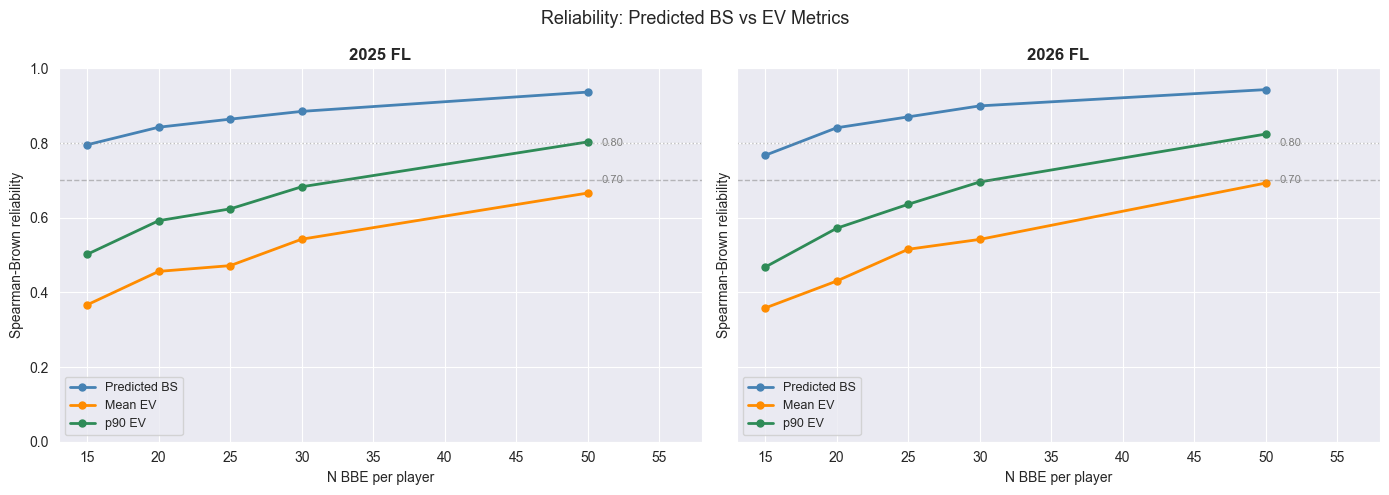


--- Stabilization point (first N >= 0.70 reliability) ---
  2025 FL | Predicted BS   : 15
  2026 FL | Predicted BS   : 15
  2025 FL | Mean EV        : not reached
  2026 FL | Mean EV        : not reached
  2025 FL | p90 EV         : 50
  2026 FL | p90 EV         : 50


In [24]:
# ---------------------------------------------------------------
# Reliability comparison: Predicted BS vs Mean EV vs p90 EV
# Spearman-Brown corrected split-half, across N BBE thresholds
# ---------------------------------------------------------------

def reliability_at_n_generic(df, col, agg_fn, n, n_iters=25, seed=42):
    """
    For a given aggregation function and N, randomly sample N BBE
    per player, split in half, correlate halves, apply Spearman-Brown.
    """
    rng   = np.random.default_rng(seed)
    valid = df.dropna(subset=[col])
    counts = valid.groupby('batter_id').size()
    keep   = counts[counts >= n].index
    sub    = valid[valid['batter_id'].isin(keep)]

    if len(keep) < 15:
        return np.nan, len(keep)

    sb_vals = []
    for _ in range(n_iters):
        sampled = (sub.groupby('batter_id', group_keys=False)
                      .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
        sampled = sampled.copy()
        sampled['half'] = rng.integers(0, 2, size=len(sampled))
        halves = (sampled.groupby(['batter_id', 'half'])[col]
                          .apply(agg_fn)
                          .unstack('half')
                          .dropna())
        if len(halves) < 10:
            continue
        r = halves[0].corr(halves[1])
        if r > -1:
            sb_vals.append(2 * r / (1 + r))

    return (np.mean(sb_vals) if sb_vals else np.nan), len(keep)


# Aggregation functions for each metric
metric_agg = {
    'Predicted BS': ('pred_z_bat_speed', a_swing_mean),
    'Mean EV':      ('launch_speed',     lambda x: x.dropna().mean() if len(x.dropna()) >= 5 else np.nan),
    'p90 EV':       ('launch_speed',     lambda x: x.dropna().quantile(0.90) if len(x.dropna()) >= 5 else np.nan),
}

# Small N grid — FL-appropriate
n_grid = [15, 20, 25, 30, 50]

# ---- 2025 FL ----
print('Running reliability curves on 2025 FL...')
rows_2025 = []
for n in n_grid:
    row = {'n_bbe': n}
    for label, (col, fn) in metric_agg.items():
        r, n_players = reliability_at_n_generic(df_2025, col, fn, n)
        row[label]            = round(r, 4) if not np.isnan(r) else np.nan
        row[f'{label}_n']     = n_players
    rows_2025.append(row)

curve_2025 = pd.DataFrame(rows_2025)

# ---- 2026 FL ----
print('Running reliability curves on 2026 FL...')
rows_2026 = []
for n in n_grid:
    row = {'n_bbe': n}
    for label, (col, fn) in metric_agg.items():
        r, n_players = reliability_at_n_generic(df_2026, col, fn, n)
        row[label]        = round(r, 4) if not np.isnan(r) else np.nan
        row[f'{label}_n'] = n_players
    rows_2026.append(row)

curve_2026 = pd.DataFrame(rows_2026)

print('\n--- Reliability curve: 2025 FL ---')
print(curve_2025[['n_bbe', 'Predicted BS', 'Mean EV', 'p90 EV',
                  'Predicted BS_n']].to_string(index=False))

print('\n--- Reliability curve: 2026 FL ---')
print(curve_2026[['n_bbe', 'Predicted BS', 'Mean EV', 'p90 EV',
                  'Predicted BS_n']].to_string(index=False))


# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = {'Predicted BS': 'steelblue', 'Mean EV': 'darkorange', 'p90 EV': 'seagreen'}

for ax, curve, title in zip(axes,
                             [curve_2025, curve_2026],
                             ['2025 FL', '2026 FL']):
    for label, color in colors.items():
        valid = curve[['n_bbe', label]].dropna()
        ax.plot(valid['n_bbe'], valid[label], marker='o', label=label,
                color=color, linewidth=2, markersize=5)

    ax.axhline(0.70, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    ax.axhline(0.80, color='gray', linestyle=':',  alpha=0.5, linewidth=1)
    ax.text(n_grid[-1] + 1, 0.70, '0.70', fontsize=8, va='center', color='gray')
    ax.text(n_grid[-1] + 1, 0.80, '0.80', fontsize=8, va='center', color='gray')
    ax.set_xlabel('N BBE per player')
    ax.set_ylabel('Spearman-Brown reliability')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_xlim(n_grid[0] - 2, n_grid[-1] + 8)

plt.suptitle('Reliability: Predicted BS vs EV Metrics', fontsize=13)
plt.tight_layout()
plt.show()

# Stabilization summary
print('\n--- Stabilization point (first N >= 0.70 reliability) ---')
for label in metrics.values():
    for name, curve in [('2025 FL', curve_2025), ('2026 FL', curve_2026)]:
        stable = curve[curve[label] >= 0.70]['n_bbe']
        pt = stable.iloc[0] if len(stable) else 'not reached'
        print(f'  {name} | {label:15s}: {pt}')

In [25]:
q_jackals = text("""
    SELECT
        batter_id,
        batter,
        exit_speed   AS launch_speed,
        angle        AS launch_angle,
        direction    AS spray_angle,
        height_in    AS height_inches,
        strikes
    FROM pitches
    WHERE date::timestamp >= '2026-01-01'
      AND date::timestamp <= '2026-12-31'
      AND batter_team = 'New Jersey Jackals'
      AND pitch_call = 'in_play'
      AND exit_speed IS NOT NULL
""")

with get_engine().connect() as conn:
    jackals = pd.read_sql(q_jackals, conn)

jackals.columns = [c.lower().strip() for c in jackals.columns]
jackals['is_2_strikes'] = (jackals['strikes'] == 2).astype(int)
jackals = jackals.dropna(subset=['launch_speed', 'launch_angle',
                                  'spray_angle', 'height_inches']).copy()

# Z-score features using Jackals pool, then predict
X_j = pd.DataFrame(index=jackals.index)
for col in features:
    X_j[col] = (jackals[col] - jackals[col].mean()) / jackals[col].std()
jackals['pred_z_bat_speed'] = model.predict(X_j)

# Aggregate
lb_jackals = (jackals.groupby(['batter_id', 'batter'])
              .agg(
                  batted_balls = ('launch_speed', 'count'),
                  ev90         = ('launch_speed', p90_ev),
                  avg_pred_bs  = ('pred_z_bat_speed', a_swing_mean),
              ).reset_index()
              .query('batted_balls >= 6')
              .dropna()
              .sort_values('ev90', ascending=False)
              .reset_index(drop=True))

lb_jackals.index += 1
lb_jackals.index.name = 'rank'

print('--- 2026 New Jersey Jackals: EV90 Leaderboard ---')
print(lb_jackals[['batter', 'batted_balls', 'ev90', 'avg_pred_bs']].to_string())

--- 2026 New Jersey Jackals: EV90 Leaderboard ---
                 batter  batted_balls        ev90  avg_pred_bs
rank                                                          
1        Stevens, Felix            51  110.584120     0.390907
2        Bellony, Isaac            32  104.497398     0.274320
3        Stuart, Daunte            64  102.787248    -0.140179
4      Maryniak, Connor            33  102.351782     0.132092
5         Gomez, Dariel            30  102.174078     0.262779
6      Figueroa, Martin            42  100.875618    -0.139030
7      Kolokie, Aldalay            40   99.240593     0.036136
8         Davis, Jakobi             7   98.379554     0.042890
9     Hernandez, Jedier            14   97.158370    -0.247240


In [27]:
# ---------------------------------------------------------------
# Bat Speed+ : scaled at BBE level, 100 = league avg, 25 = 1 SD
# Use the full FL pool (both years combined) as the baseline
# ---------------------------------------------------------------

# 1. Compute baseline from combined 2025 + 2026 FL predictions
all_preds = pd.concat([
    df_2025['pred_z_bat_speed'],
    df_2026['pred_z_bat_speed'],
]).dropna()

BS_PLUS_MU    = all_preds.mean()
BS_PLUS_SIGMA = all_preds.std()

print(f'FL baseline  mu={BS_PLUS_MU:.4f}  sigma={BS_PLUS_SIGMA:.4f}')

# 2. Apply to each dataset at the BBE level
for df in [df_2025, df_2026, jackals_2025, jackals]:
    df['bat_speed_plus'] = (
        (df['pred_z_bat_speed'] - BS_PLUS_MU) / BS_PLUS_SIGMA * 25 + 100
    ).round(1)

# 3. Player aggregation: a_swing_mean of BBE-level Bat Speed+
#    (equivalent to what you had before, just on the scaled values)
def agg_bs_plus(df, min_bbe=6):
    return (df.groupby(['batter_id', 'batter'])
              .agg(
                  batted_balls  = ('bat_speed_plus', 'count'),
                  bat_speed_plus = ('bat_speed_plus', a_swing_mean),
                  ev90           = ('launch_speed',   p90_ev),
              ).reset_index()
              .query('batted_balls >= @min_bbe')
              .dropna(subset=['bat_speed_plus']))

lb_2025_plus = agg_bs_plus(df_2025,     min_bbe=25)
lb_2026_plus = agg_bs_plus(df_2026,     min_bbe=12)
jk_2025_plus = agg_bs_plus(jackals_2025, min_bbe=6)
jk_2026_plus = agg_bs_plus(jackals,      min_bbe=6)

# 4. Leaderboards
print('\n--- 2025 FL Bat Speed+ (top 20) ---')
print(lb_2025_plus.sort_values('bat_speed_plus', ascending=False)
                  .head(20).to_string(index=False))

print('\n--- 2026 FL Bat Speed+ (top 20) ---')
print(lb_2026_plus.sort_values('bat_speed_plus', ascending=False)
                  .head(20).to_string(index=False))

# 5. Jackals YoY
jk_yoy = (jk_2025_plus.add_suffix('_2025')
           .rename(columns={'batter_id_2025': 'batter_id', 'batter_2025': 'batter'})
           .merge(
               jk_2026_plus.add_suffix('_2026')
               .rename(columns={'batter_id_2026': 'batter_id', 'batter_2026': 'batter'}),
               on=['batter_id', 'batter'], how='outer'
           ))

jk_yoy['delta']  = (jk_yoy['bat_speed_plus_2026'] - jk_yoy['bat_speed_plus_2025']).round(1)
jk_yoy['status'] = 'returning'
jk_yoy.loc[jk_yoy['bat_speed_plus_2025'].isna(), 'status'] = 'new'
jk_yoy.loc[jk_yoy['bat_speed_plus_2026'].isna(), 'status'] = 'departed'

print('\n--- Jackals Bat Speed+ YoY ---')
print(jk_yoy[['batter', 'status',
              'batted_balls_2025', 'bat_speed_plus_2025',
              'batted_balls_2026', 'bat_speed_plus_2026',
              'delta']].sort_values('bat_speed_plus_2026', ascending=False)
             .to_string(index=False))

FL baseline  mu=-0.0505  sigma=0.6975

--- 2025 FL Bat Speed+ (top 20) ---
 batter_id            batter  batted_balls  bat_speed_plus       ev90
    681376   Hylton, Brandon           251      131.583191 103.893160
1000069758     Czech, Andrew           212      123.601585 105.416280
    683106  Backstrom, Mahki           177      123.586876 110.880916
    702125  Calarco, Anthony           309      118.770248 107.947404
    642268   Tapia, Emmanuel           166      117.032219 106.372480
    665023    Spillane, Bren            68      116.868851 105.294437
    803325  Adams, Christian            28      116.220001 102.625525
1000132019     Quinn, Jaidan            59      116.007538 104.977610
1000132032   Cardoso, Kaiden           124      115.737823 102.402328
    701321     Calarco, Alex            64      115.335091 103.516723
    676627     Reed, Tyreque           198      115.139328 106.568296
   8881054  Brocato, Anthony           132      115.113571 106.183751
1000119548     

In [33]:
jk_2026_plus

,batter_id,batter,batted_balls,bat_speed_plus,ev90
1,649810,"Gomez, Dariel",30,113.518517,102.174078
2,676953,"Figueroa, Martin",42,99.791893,100.875618
3,683058,"Bellony, Isaac",32,116.039291,104.497398
4,685474,"Stevens, Felix",51,122.467392,110.584120
6,690715,"Stuart, Daunte",64,105.503502,102.787248
7,801877,"Hernandez, Jedier",14,99.116669,97.158370
8,813985,"Kolokie, Aldalay",40,105.711121,99.240593
9,831880,"Maryniak, Connor",33,108.582764,102.351782
10,836013,"Davis, Jakobi",7,106.716667,98.379554


43,047 BBE  |  382 batters

Zone distribution:
zone
pull      0.837
center    0.148
oppo      0.015
Name: proportion, dtype: float64
Air ball rate:  0.536
Pull Air% (lg): 0.497


C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: F


--- Pull Air% reliability curve (2025 FL) ---
 n_bbe  reliability  n_players
     6          NaN        353
    10       0.0840        342
    15       0.2131        323
    20       0.2001        307
    25       0.2522        289
    30       0.2874        278
    50       0.4005        240
    75       0.4826        209

Stabilizes (>=0.70) at N = not reached


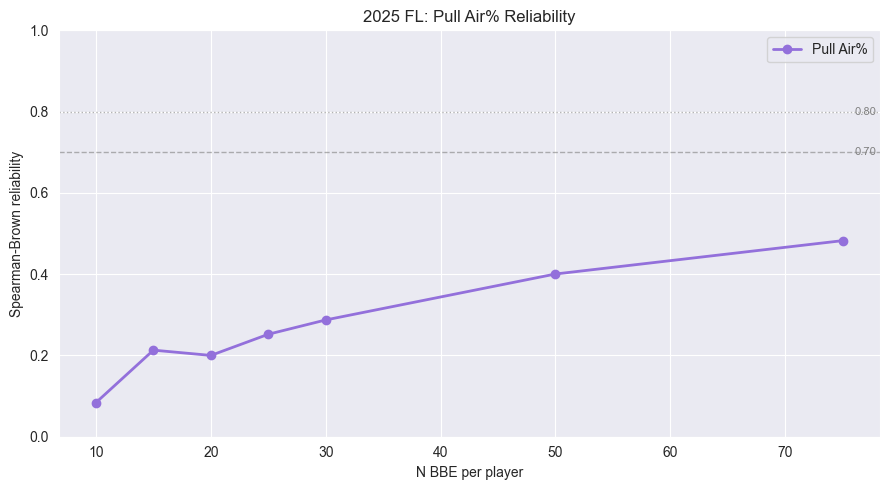

In [29]:
# ---------------------------------------------------------------
# Pull Air% reliability analysis — standalone
# ---------------------------------------------------------------
q_pa = text("""
    SELECT
        batter_id,
        batter,
        batter_side,
        direction,
        angle   AS launch_angle
    FROM pitches
    WHERE date::timestamp >= '2025-01-01'
      AND date::timestamp <= '2025-12-31'
      AND pitch_call = 'in_play'
      AND direction IS NOT NULL
      AND angle IS NOT NULL
      AND batter_side IN ('left', 'right', 'Left', 'Right')
""")

with get_engine().connect() as conn:
    df_pa = pd.read_sql(q_pa, conn)

df_pa.columns        = [c.lower().strip() for c in df_pa.columns]
df_pa['batter_side'] = df_pa['batter_side'].str.lower()
df_pa = df_pa.dropna(subset=['launch_angle', 'direction']).copy()

# Mirror so pull = positive for both hands
df_pa['direction_mirrored'] = np.where(
    df_pa['batter_side'] == 'left',
    -df_pa['direction'],
     df_pa['direction']
)

# Zone + air flags
df_pa['zone']        = pd.cut(df_pa['direction_mirrored'],
                               bins=[-91, -60, -30, 91],
                               labels=['oppo', 'center', 'pull'])
df_pa['is_air']      = (df_pa['launch_angle'] >= 10).astype(int)
df_pa['is_pull_air'] = ((df_pa['zone'] == 'pull') & (df_pa['is_air'] == 1)).astype(int)

print(f'{len(df_pa):,} BBE  |  {df_pa["batter_id"].nunique()} batters')
print(f'\nZone distribution:')
print(df_pa['zone'].value_counts(normalize=True).round(3))
print(f'Air ball rate:  {df_pa["is_air"].mean():.3f}')
print(f'Pull Air% (lg): {df_pa["is_pull_air"].mean():.3f}')



In [30]:
# Check direction sign convention using known pull hitters
# Pull hitters should cluster on one side, oppo the other

# Get a few LHH and RHH with enough BBE
sample = (df_pa.groupby(['batter', 'batter_side'])
               .agg(
                   bbe=('direction', 'count'),
                   mean_dir=('direction', 'mean'),
                   p25_dir=('direction', lambda x: x.quantile(0.25)),
                   p75_dir=('direction', lambda x: x.quantile(0.75)),
               )
               .reset_index()
               .query('bbe >= 25')
               .sort_values(['batter_side', 'mean_dir']))

print('--- RHH: sorted by mean direction ---')
print(sample[sample['batter_side'] == 'right']
      .head(10).to_string(index=False))

print('\n--- LHH: sorted by mean direction ---')
print(sample[sample['batter_side'] == 'left']
      .head(10).to_string(index=False))

# Also check overall distribution by side
print('\nMean direction by handedness:')
print(df_pa.groupby('batter_side')['direction'].describe().round(2))

--- RHH: sorted by mean direction ---
             batter batter_side  bbe   mean_dir    p25_dir   p75_dir
    Estrada, Willie       right   47 -21.111034 -33.134487 -4.718460
       Larry, Amani       right  193 -17.170449 -30.042744 -1.468700
Negret, Juan Carlos       right  135 -16.495415 -32.933339 -3.465934
 Kuzemka, Christian       right  150 -15.820644 -30.330019  1.580038
      Curbelo, Luis       right  131 -15.548445 -31.765299 -3.144761
    Contreras, Jose       right  107 -15.259137 -29.147638  0.592851
        DeLeo, Jake       right  143 -15.030515 -28.562751 -3.582005
    McCarthy, Nolan       right   77 -14.841015 -30.473800  1.836656
     Fiorenza, John       right   26 -14.753284 -31.150594  2.027377
    Espinal, Walner       right   37 -14.723727 -25.146235  2.975668

--- LHH: sorted by mean direction ---
             batter batter_side  bbe   mean_dir    p25_dir    p75_dir
      Smith, Jaylen        left   50 -23.901711 -38.972074 -10.550463
Piatkiewicz, Jeremy     

In [31]:
# Mirror RHH so pull = positive for both hands
df_pa['direction_mirrored'] = np.where(
    df_pa['batter_side'] == 'right',
    -df_pa['direction'],
     df_pa['direction']
)

# Zone assignment: -45 to 45 split into three 30-degree thirds
df_pa['zone'] = pd.cut(df_pa['direction_mirrored'],
                        bins=[-46, -15, 15, 46],
                        labels=['oppo', 'center', 'pull'])

df_pa['is_air']      = (df_pa['launch_angle'] >= 10).astype(int)
df_pa['is_pull_air'] = ((df_pa['zone'] == 'pull') & (df_pa['is_air'] == 1)).astype(int)

# Sanity check at player level — pull hitters should be at the top
check = (df_pa.groupby(['batter', 'batter_side'])
              .agg(
                  bbe          = ('zone', 'count'),
                  pull_rate    = ('zone', lambda x: (x == 'pull').mean()),
                  pull_air_pct = ('is_pull_air', 'mean'),
                  mean_dir_raw = ('direction', 'mean'),
              )
              .reset_index()
              .query('bbe >= 25')
              .sort_values('pull_rate', ascending=False))

print('--- Top 10 pull hitters (sanity check) ---')
print(check.head(10).to_string(index=False))
print('\n--- Bottom 10 (oppo hitters) ---')
print(check.tail(10).to_string(index=False))

print('\nZone distribution (should be roughly equal thirds):')
print(df_pa['zone'].value_counts(normalize=True).round(3))
print(f'\nLeague Pull Air%: {df_pa["is_pull_air"].mean():.3f}')

--- Top 10 pull hitters (sanity check) ---
             batter batter_side  bbe  pull_rate  pull_air_pct  mean_dir_raw
      Curbelo, Luis       right  123   0.580153      0.412214    -15.548445
   Paolini, Stephen        left   28   0.535714      0.321429     10.506077
   Norman, Satchell       right   61   0.523810      0.365079    -12.776471
    Tapia, Emmanuel        left  153   0.500000      0.253012     18.350122
        DeLeo, Jake       right  134   0.489510      0.237762    -15.030515
Negret, Juan Carlos       right  124   0.488889      0.244444    -16.495415
      Scanlon, Jack        left  123   0.488372      0.279070     14.543372
      Gomez, Miguel        left   80   0.488095      0.190476     15.591979
   Goldstein, Dylan        left   98   0.485437      0.310680     13.844164
     Wright, Taylor        left  144   0.480519      0.207792     15.783071

--- Bottom 10 (oppo hitters) ---
             batter batter_side  bbe  pull_rate  pull_air_pct  mean_dir_raw
      White

C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_8732\2512572457.py:23: F

--- Pull Air% reliability curve (2025 FL) ---
 n_bbe  reliability  n_players
     6          NaN        353
    10       0.0958        342
    15       0.2115        323
    20       0.2677        307
    25       0.3325        289
    30       0.3748        278
    50       0.5393        240
    75       0.6403        209

Stabilizes (>=0.70) at N = not reached


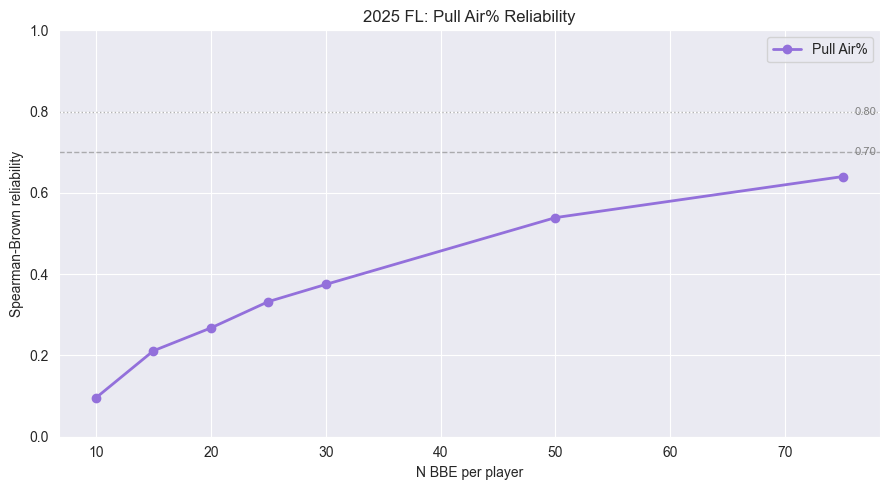

In [32]:
pull_air_fn = lambda x: x.dropna().mean() if len(x.dropna()) >= 5 else np.nan

n_grid = [6, 10, 15, 20, 25, 30, 50, 75]
rows   = []
for n in n_grid:
    r, n_players = reliability_at_n_generic(df_pa, 'is_pull_air', pull_air_fn, n)
    rows.append({
        'n_bbe':       n,
        'reliability': round(r, 4) if not np.isnan(r) else np.nan,
        'n_players':   n_players,
    })

curve = pd.DataFrame(rows)
print('--- Pull Air% reliability curve (2025 FL) ---')
print(curve.to_string(index=False))

stable = curve[curve['reliability'] >= 0.70]['n_bbe']
print(f'\nStabilizes (>=0.70) at N = {stable.iloc[0] if len(stable) else "not reached"}')

fig, ax = plt.subplots(figsize=(9, 5))
valid = curve.dropna(subset=['reliability'])
ax.plot(valid['n_bbe'], valid['reliability'], marker='o',
        color='mediumpurple', linewidth=2, markersize=6, label='Pull Air%')
ax.axhline(0.70, color='gray', linestyle='--', alpha=0.6, linewidth=1)
ax.axhline(0.80, color='gray', linestyle=':',  alpha=0.6, linewidth=1)
ax.text(n_grid[-1] + 1, 0.70, '0.70', fontsize=8, va='center', color='gray')
ax.text(n_grid[-1] + 1, 0.80, '0.80', fontsize=8, va='center', color='gray')
ax.set_xlabel('N BBE per player')
ax.set_ylabel('Spearman-Brown reliability')
ax.set_title('2025 FL: Pull Air% Reliability')
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()